# Automated Customer Support Ticket Classification and Priority Routing System

## Introduction

This project uses Machine Learning to classify customer support tickets and identify their priority levels automatically. It uses a dataset containing 2,800 customer support records. Two Random Forest classification models are trained: one predicts the ticket type, and the other predicts the priority. Based on the predicted priority, a rule-based routing system assigns the ticket to the appropriate support team.

## Objectives

- Automatically predict the type of customer support ticket.
- Identify the urgency level of each ticket.
- Assign tickets to suitable support teams using routing rules.
- Visualize the dataset and evaluate model performance.
- Reduce manual work and support faster ticket handling.

## Step 1: Importing Libraries

We import the required Python libraries for data processing, machine learning, model saving, and visualization.

- **Pandas:** Loads and manages the dataset.
- **NumPy:** Supports numerical operations.
- **Scikit-learn:** Preprocesses data, trains models, and evaluates predictions.
- **Joblib:** Saves the trained machine learning models.
- **Matplotlib and Seaborn:** Create charts and visualizations.
- **Streamlit:** Can be used later to create a web interface.

In [4]:
pip install pandas numpy scikit-learn joblib streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 49.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 70.2 MB/s eta 0:00:00


In [5]:
from google.colab import files

uploaded = files.upload()

Saving ML cloud Dataset.csv to ML cloud Dataset.csv


## Step 2. Data Preprocessing

Data preprocessing is the process of cleaning and preparing the dataset before training the machine learning model. In this project, Pandas is used to load the dataset, remove duplicate records, and delete rows containing missing values. This helps improve data quality and prepares the dataset for model training.

In [6]:
import pandas as pd

df = pd.read_csv("ML cloud Dataset.csv")

print("Dataset Shape:", df.shape)
print(df.head())

Dataset Shape: (2800, 11)
   ticket_id ticket_type  priority channel  customer_tenure_months  \
0          1     Product    Medium    Chat                      99   
1          2       Other  Critical   Email                      60   
2          3     Account    Medium   Phone                      58   
3          4       Other       Low   Email                      12   
4          5       Other       Low   Phone                      88   

   agent_experience_years  messages_count  avg_response_time_minutes  \
0                     7.4               9                       55.9   
1                     3.9              20                       19.8   
2                     3.6              45                       25.1   
3                     5.0              28                       42.6   
4                     8.8              20                       19.0   

   resolution_time_hours  escalated  customer_satisfaction_score  
0                   39.7          0                  

In [7]:
print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset Shape: (2800, 11)

Columns:
['ticket_id', 'ticket_type', 'priority', 'channel', 'customer_tenure_months', 'agent_experience_years', 'messages_count', 'avg_response_time_minutes', 'resolution_time_hours', 'escalated', 'customer_satisfaction_score']


,ticket_id,ticket_type,priority,channel,customer_tenure_months,agent_experience_years,messages_count,avg_response_time_minutes,resolution_time_hours,escalated,customer_satisfaction_score
0,1,Product,Medium,Chat,99,7.4,9,55.9,39.7,0,3
1,2,Other,Critical,Email,60,3.9,20,19.8,6.9,1,2
2,3,Account,Medium,Phone,58,3.6,45,25.1,59.8,0,1
3,4,Other,Low,Email,12,5.0,28,42.6,45.9,0,3
4,5,Other,Low,Phone,88,8.8,20,19.0,40.5,0,1


## Step 3: Data Cleaning

We check for missing values in every column. Missing values can affect the quality of machine learning results. After checking the dataset, we remove rows containing missing values, if any are present.

In our dataset, no missing values were found, so all 2,800 records were retained.

In [8]:
print(df.isnull().sum())

ticket_id                      0
ticket_type                    0
priority                       0
channel                        0
customer_tenure_months         0
agent_experience_years         0
messages_count                 0
avg_response_time_minutes      0
resolution_time_hours          0
escalated                      0
customer_satisfaction_score    0
dtype: int64


## Step 4: Dataset Loading and Exploration

The dataset contains 2,800 rows and 11 columns. Each row represents one customer support ticket. The columns include ticket type, priority, communication channel, customer tenure, response time, resolution time, escalation status, and customer satisfaction.

We inspect the dataset shape, column names, and first few records to understand the available information before training the models.

In [9]:
df = df.dropna()

print("Shape after cleaning:", df.shape)

Shape after cleaning: (2800, 11)


## Step 5. Feature Selection

Feature selection identifies the input features and target variables required for the machine learning model. In this project, `ticket_id` is removed because it is only an identifier. The remaining features, such as support channel, customer tenure, agent experience, message count, and response time, are used as input data. The target variables are `ticket_type` and `priority`, which help predict the category and priority level of customer support tickets.

## Step 6: Training and Testing Split

We divide the dataset into 80% training data and 20% testing data. The training data helps the models learn patterns, while the testing data evaluates their performance on records not used during training.

For 2,800 records, approximately 2,240 records are used for training and 560 records for testing. We use `random_state=42` to make the split reproducible and `stratify` to preserve the target class proportions.

## Step 7: Ticket Type Classification

We train a Random Forest classifier to predict the type of customer support ticket. The possible categories in our dataset include Account, Billing, Other, Product, and Technical.

The model learns patterns from the input features and predicts the most likely ticket category for a new ticket. After training, we evaluate the model using accuracy, precision, recall, and F1-score. The trained model is saved as `ticket_type_model.pkl` for reuse.

In [10]:
import numpy as np
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Remove ID
data = df.drop(columns=["ticket_id"])

# Features and target
X = data.drop(columns=["ticket_type", "priority"])
y = data["ticket_type"]

categorical_features = ["channel"]

numeric_features = [
    "customer_tenure_months",
    "agent_experience_years",
    "messages_count",
    "avg_response_time_minutes",
    "resolution_time_hours",
    "escalated",
    "customer_satisfaction_score"
]

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("num", StandardScaler(), numeric_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Ticket Type Accuracy:",
      accuracy_score(y_test, predictions))

print("\nClassification Report:")
print(classification_report(y_test, predictions))

joblib.dump(model, "ticket_type_model.pkl")

print("\nTicket Type Model Saved!")

Ticket Type Accuracy: 0.19642857142857142

Classification Report:
              precision    recall  f1-score   support

     Account       0.15      0.13      0.14       106
     Billing       0.21      0.20      0.20       111
       Other       0.15      0.16      0.15       113
     Product       0.29      0.31      0.30       116
   Technical       0.18      0.18      0.18       114

    accuracy                           0.20       560
   macro avg       0.19      0.20      0.19       560
weighted avg       0.20      0.20      0.20       560


Ticket Type Model Saved!


Ticket Type Classification Accuracy: 19.64%

Classification Report:
              precision    recall  f1-score   support

     Account       0.15      0.13      0.14       106
     Billing       0.21      0.20      0.20       111
       Other       0.15      0.16      0.15       113
     Product       0.29      0.31      0.30       116
   Technical       0.18      0.18      0.18       114

    accuracy                           0.20       560
   macro avg       0.19      0.20      0.19       560
weighted avg       0.20      0.20      0.20       560



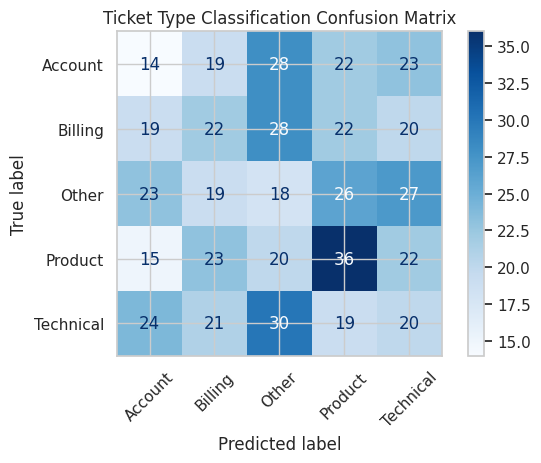

In [21]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report,
    ConfusionMatrixDisplay
)

# Load dataset
df = pd.read_csv("ML cloud Dataset.csv")
df = df.dropna()

# Select features and target
X = df.drop(columns=["ticket_id", "ticket_type", "priority"])
y = df["ticket_type"]

categorical_features = ["channel"]

numeric_features = [
    "customer_tenure_months",
    "agent_experience_years",
    "messages_count",
    "avg_response_time_minutes",
    "resolution_time_hours",
    "escalated",
    "customer_satisfaction_score"
]

# Preprocessing
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     categorical_features),
    ("num", StandardScaler(), numeric_features)
])

# Create classification model
ticket_type_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ))
])

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train model
ticket_type_model.fit(X_train, y_train)

# Predict ticket type
y_pred = ticket_type_model.predict(X_test)

# Display accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Ticket Type Classification Accuracy: {accuracy * 100:.2f}%")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion matrix visualization
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["Account", "Billing", "Other", "Product", "Technical"],
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Ticket Type Classification Confusion Matrix")
plt.tight_layout()
plt.show()


## Step 8: Priority Classification

A second Random Forest classifier predicts the priority of each ticket. The priority categories are Critical, High, Medium, and Low.

This model uses the same input features but learns to predict the `priority` target variable. We evaluate its performance using accuracy, precision, recall, and F1-score. The trained model is saved as `priority_model.pkl`.

In [20]:
X = data.drop(columns=["ticket_type", "priority"])
y = data["priority"]

priority_model = Pipeline([
    ("preprocessor", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", StandardScaler(), numeric_features)
    ])),

    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

priority_model.fit(X_train, y_train)

predictions = priority_model.predict(X_test)

print("Priority Accuracy:",
      accuracy_score(y_test, predictions))

print("\nClassification Report:")
print(classification_report(y_test, predictions))

joblib.dump(priority_model, "priority_model.pkl")

print("\nPriority Model Saved!")

Priority Accuracy: 0.25892857142857145

Classification Report:
              precision    recall  f1-score   support

    Critical       0.26      0.24      0.25       140
        High       0.31      0.30      0.31       141
         Low       0.22      0.25      0.23       146
      Medium       0.25      0.24      0.24       133

    accuracy                           0.26       560
   macro avg       0.26      0.26      0.26       560
weighted avg       0.26      0.26      0.26       560


Priority Model Saved!


Priority Classification Accuracy: 25.89%

Classification Report:
              precision    recall  f1-score   support

    Critical       0.26      0.24      0.25       140
        High       0.31      0.30      0.31       141
         Low       0.22      0.25      0.23       146
      Medium       0.25      0.24      0.24       133

    accuracy                           0.26       560
   macro avg       0.26      0.26      0.26       560
weighted avg       0.26      0.26      0.26       560



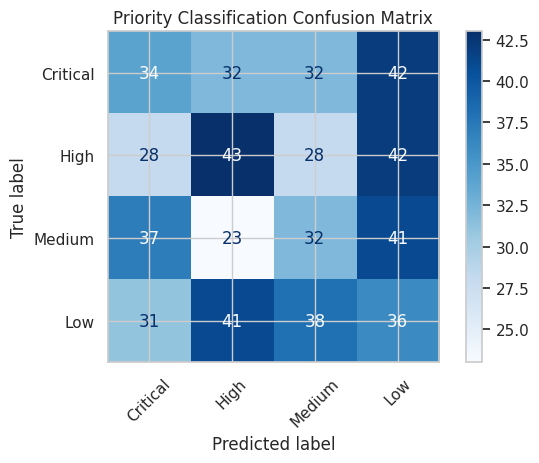

In [18]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report,
    ConfusionMatrixDisplay
)

# Load dataset
df = pd.read_csv("ML cloud Dataset.csv")
df = df.dropna()

# Select features and target
X = df.drop(columns=["ticket_id", "ticket_type", "priority"])
y = df["priority"]

categorical_features = ["channel"]

numeric_features = [
    "customer_tenure_months",
    "agent_experience_years",
    "messages_count",
    "avg_response_time_minutes",
    "resolution_time_hours",
    "escalated",
    "customer_satisfaction_score"
]

# Preprocessing
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     categorical_features),
    ("num", StandardScaler(), numeric_features)
])

# Create classification model
priority_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ))
])

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train model
priority_model.fit(X_train, y_train)

# Predict priority
y_pred = priority_model.predict(X_test)

# Display accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Priority Classification Accuracy: {accuracy * 100:.2f}%")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion matrix visualization
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["Critical", "High", "Medium", "Low"],
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Priority Classification Confusion Matrix")
plt.tight_layout()
plt.show()


## Step 9: Data Visualization

We use Matplotlib and Seaborn to visualize the dataset. The charts show the distribution of ticket categories, priority levels, support channels, and customer satisfaction scores.

These visualizations help us understand the dataset, identify class distributions, and present the data in an easy-to-understand format.

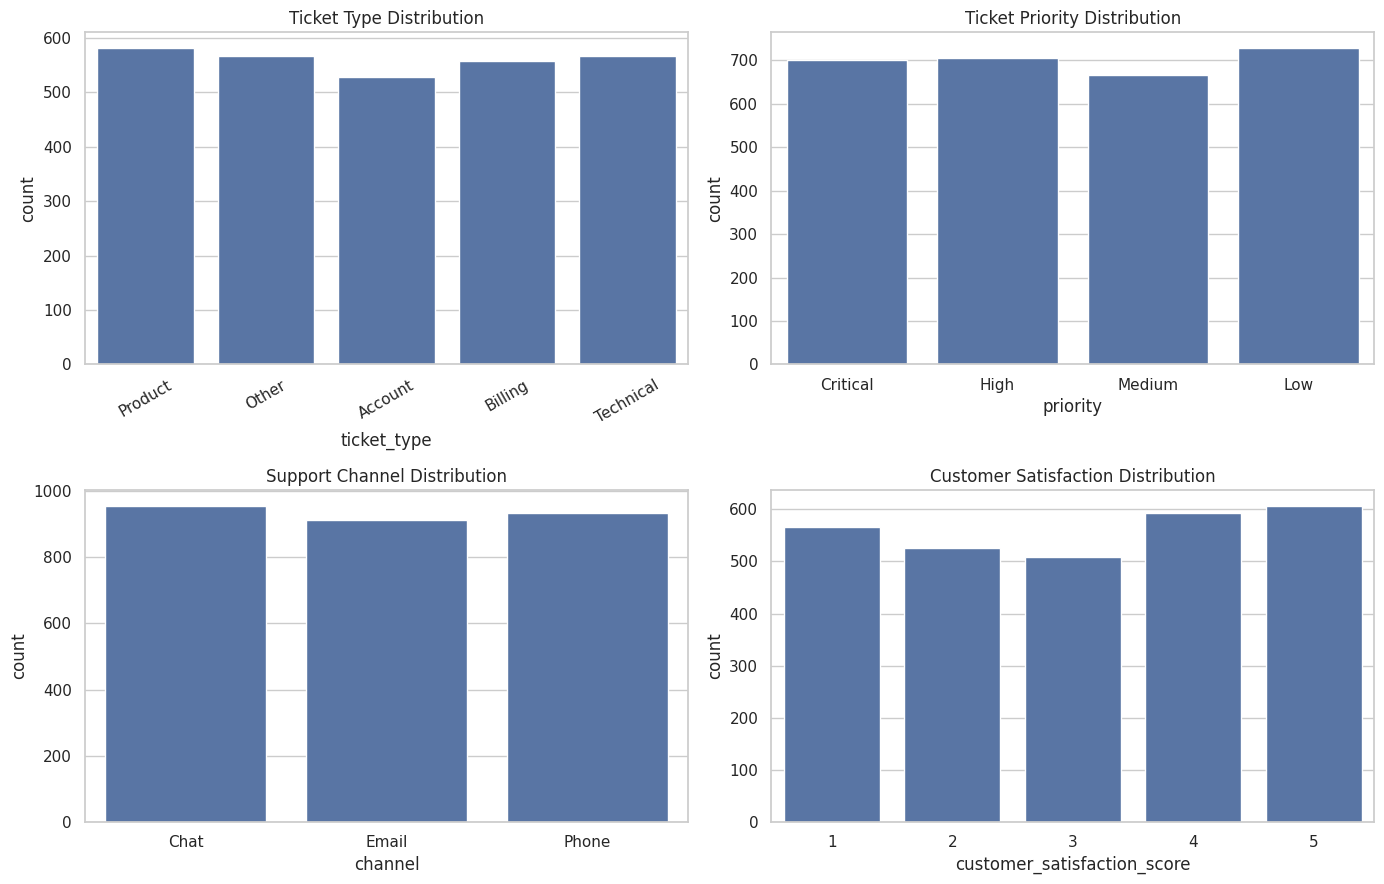

In [16]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("ML cloud Dataset.csv")

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.countplot(data=df, x="ticket_type", ax=axes[0, 0])
axes[0, 0].set_title("Ticket Type Distribution")
axes[0, 0].tick_params(axis="x", rotation=30)

sns.countplot(
    data=df,
    x="priority",
    order=["Critical", "High", "Medium", "Low"],
    ax=axes[0, 1]
)
axes[0, 1].set_title("Ticket Priority Distribution")

sns.countplot(data=df, x="channel", ax=axes[1, 0])
axes[1, 0].set_title("Support Channel Distribution")

sns.countplot(
    data=df,
    x="customer_satisfaction_score",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Customer Satisfaction Distribution")

plt.tight_layout()
plt.show()


## Step 10: Model Performance Visualization

We compare the accuracy of the Ticket Type model and the Priority model using a bar chart.

In the current run, the Ticket Type model achieved approximately 19.64% accuracy, while the Priority model achieved approximately 25.89% accuracy. These results indicate that the models have limited predictive performance and may require better features, improved data quality, or further model tuning.

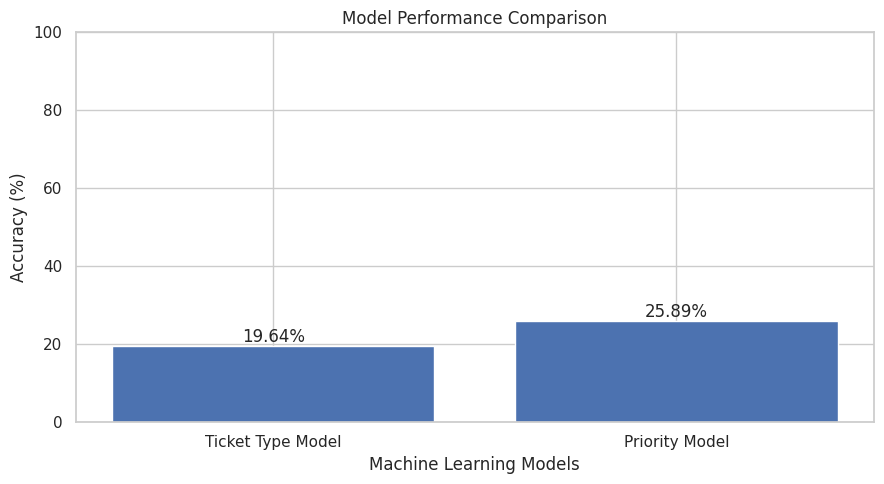

Ticket Type Accuracy: 19.64%
Priority Accuracy: 25.89%


In [17]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

df = df.dropna()

X = df.drop(columns=["ticket_id", "ticket_type", "priority"])

categorical_features = ["channel"]
numeric_features = [
    "customer_tenure_months",
    "agent_experience_years",
    "messages_count",
    "avg_response_time_minutes",
    "resolution_time_hours",
    "escalated",
    "customer_satisfaction_score"
]

def create_model():
    preprocessor = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
        ("num", StandardScaler(), numeric_features)
    ])

    return Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200, random_state=42
        ))
    ])

# Ticket Type Model
X_train, X_test, y_train, y_test = train_test_split(
    X, df["ticket_type"], test_size=0.2,
    random_state=42, stratify=df["ticket_type"]
)

ticket_model = create_model()
ticket_model.fit(X_train, y_train)

ticket_accuracy = accuracy_score(
    y_test, ticket_model.predict(X_test)
)

# Priority Model
Xp_train, Xp_test, yp_train, yp_test = train_test_split(
    X, df["priority"], test_size=0.2,
    random_state=42, stratify=df["priority"]
)

priority_model = create_model()
priority_model.fit(Xp_train, yp_train)

priority_accuracy = accuracy_score(
    yp_test, priority_model.predict(Xp_test)
)

# Plot accuracy comparison
names = ["Ticket Type Model", "Priority Model"]
scores = [ticket_accuracy * 100, priority_accuracy * 100]

plt.figure(figsize=(9, 5))
bars = plt.bar(names, scores)

plt.title("Model Performance Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for bar, score in zip(bars, scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{score:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

print(f"Ticket Type Accuracy: {ticket_accuracy * 100:.2f}%")
print(f"Priority Accuracy: {priority_accuracy * 100:.2f}%")


## Step 11: Prediction for a New Customer Support Ticket

We create a sample ticket using input values such as Email channel, customer tenure, agent experience, message count, response time, resolution time, escalation status, and customer satisfaction.

The trained models predict the ticket type and priority for this new record. For the sample input used in our current experiment, the output is Account for ticket type and Critical for priority.

These are model predictions, not guaranteed correct classifications.

In [ ]:
new_ticket = pd.DataFrame({
    "channel": ["Email"],
    "customer_tenure_months": [36],
    "agent_experience_years": [3],
    "messages_count": [25],
    "avg_response_time_minutes": [40],
    "resolution_time_hours": [20],
    "escalated": [1],
    "customer_satisfaction_score": [2]
})

ticket_type = model.predict(new_ticket)[0]
priority = priority_model.predict(new_ticket)[0]

print("Predicted Ticket Type:", ticket_type)
print("Predicted Priority:", priority)

Predicted Ticket Type: Account
Predicted Priority: Critical


## Step 12: Rule-Based Ticket Routing

After predicting the priority, we use a dictionary containing routing rules to assign the ticket to a suitable support team.

- Critical → Senior Support / Escalation Team
- High → Priority Support Team
- Medium → Standard Support Team
- Low → General Support Team

The routing process is rule-based rather than a third machine learning prediction. It uses the priority predicted by the model to determine the assigned team.

## Step 13: Final Prediction Result

The system produces three outputs:

- **Ticket Type: Account** — the first model predicts the ticket category.
- **Priority: Critical** — the second model predicts the urgency level.
- **Route To: Senior Support / Escalation Team** — the routing rules assign the ticket to the appropriate team based on its predicted priority.

This demonstrates how machine learning predictions and rule-based logic can work together to automate customer support ticket classification and routing.

In [ ]:
routing = {
    "Critical": "Senior Support / Escalation Team",
    "High": "Priority Support Team",
    "Medium": "Standard Support Team",
    "Low": "General Support Team"
}

assigned_team = routing.get(
    priority,
    "General Support Team"
)

print("\n===== FINAL RESULT =====")
print("Ticket Type :", ticket_type)
print("Priority    :", priority)
print("Route To    :", assigned_team)


===== FINAL RESULT =====
Ticket Type : Account
Priority    : Critical
Route To    : Senior Support / Escalation Team


## Data Flow of the Proposed System

The data flow diagram explains the step-by-step working of the Automated Customer Support Ticket Classification and Priority Routing System.

**1. Customer Support Ticket Dataset:** The system uses a dataset containing 2,800 customer support ticket records for training and testing the machine learning models.

**2. Data Preprocessing:** Duplicate records and rows containing missing values are removed to improve data quality.

**3. Feature Selection:** Relevant input features, such as support channel, customer tenure, agent experience, and response time, are selected. The target variables are ticket type and priority.

**4. Data Splitting:** The dataset is divided into 80% training data and 20% testing data. The training data is used to train the models, while the testing data is used to evaluate their performance.

**5. Random Forest Classification Models:** Two separate Random Forest models are trained to classify ticket types and predict ticket priority.

**6. Ticket Type and Priority Prediction:** The trained models predict the category and priority level of a customer support ticket.

**7. Routing Rules:** Based on the predicted priority, predefined rules select the appropriate support team. Critical tickets are assigned to the Senior Support or Escalation Team, while lower-priority tickets are directed to the corresponding support teams.

**8. Assigned Support Team and Results:** The system displays the predicted ticket type, priority level, and assigned support team, helping organize customer support requests efficiently.

**Conclusion:** The data flow illustrates how the dataset is processed, classified, and routed to the appropriate support team using machine learning and predefined routing rules.

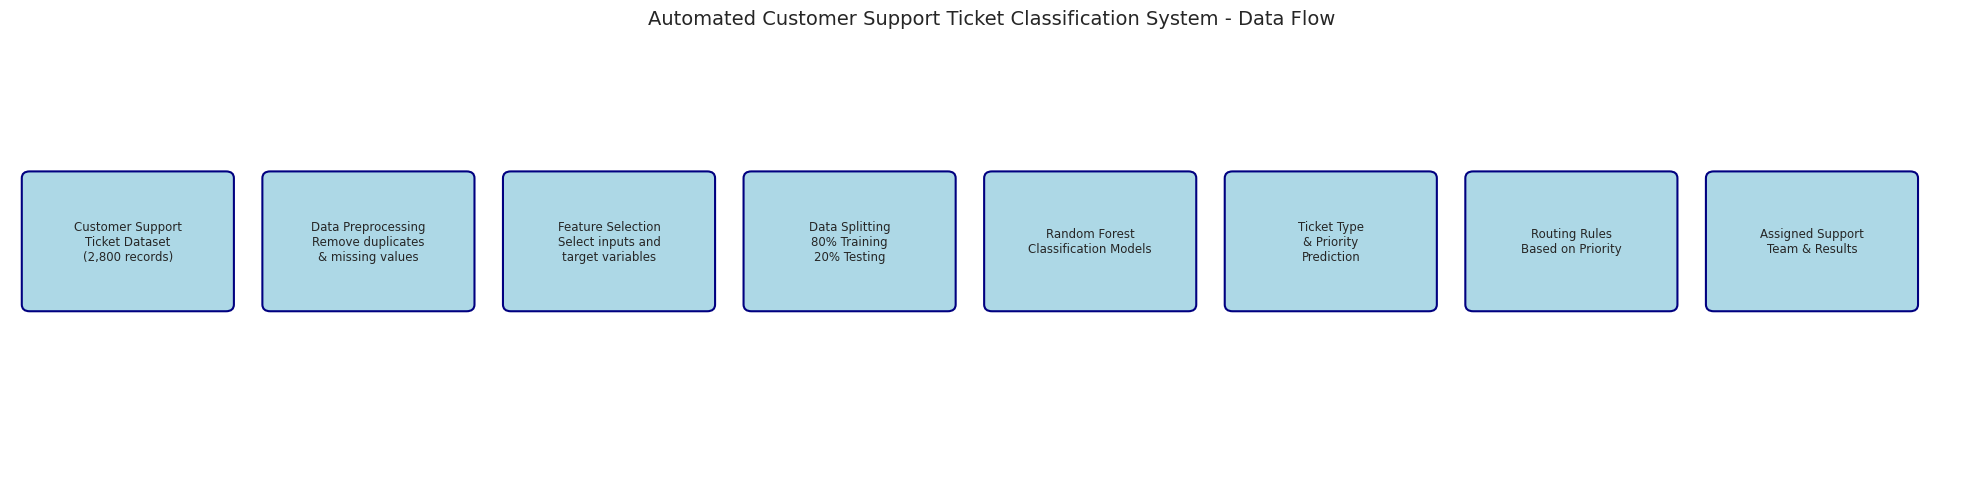

In [22]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

steps = [
    "Customer Support\nTicket Dataset\n(2,800 records)",
    "Data Preprocessing\nRemove duplicates\n& missing values",
    "Feature Selection\nSelect inputs and\ntarget variables",
    "Data Splitting\n80% Training\n20% Testing",
    "Random Forest\nClassification Models",
    "Ticket Type\n& Priority\nPrediction",
    "Routing Rules\nBased on Priority",
    "Assigned Support\nTeam & Results"
]

fig, ax = plt.subplots(figsize=(20, 5))
ax.set_xlim(0, 20)
ax.set_ylim(0, 5)
ax.axis("off")

positions = [
    (0.2, 2.0), (2.65, 2.0), (5.1, 2.0), (7.55, 2.0),
    (10.0, 2.0), (12.45, 2.0), (14.9, 2.0), (17.35, 2.0)
]

for i, (step, (x, y)) in enumerate(zip(steps, positions)):
    box = FancyBboxPatch(
        (x, y), 2.0, 1.5,
        boxstyle="round,pad=0.08",
        facecolor="lightblue",
        edgecolor="navy",
        linewidth=1.5
    )
    ax.add_patch(box)
    ax.text(
        x + 1, y + 0.75, step,
        ha="center", va="center", fontsize=8.5
    )

    if i < len(steps) - 1:
        ax.annotate(
            "",
            xy=(positions[i + 1][0] - 0.08, y + 0.75),
            xytext=(x + 2.08, y + 0.75),
            arrowprops=dict(arrowstyle="->", lw=1.5)
        )

ax.set_title(
    "Automated Customer Support Ticket Classification System - Data Flow",
    fontsize=14,
    pad=20
)

plt.tight_layout()
plt.show()
